In [3]:
pip install pmdarima statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.9/591.9 kB 4.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 4.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 8.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pmdarima]1/3 [Cython]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error ,mean_absolute_error,mean_absolute_percentage_error
import warnings
warnings.filterwarnings("ignore")


In [19]:
data = pd.read_csv("/Users/arjunaji/BIA ARJUN/ML/datasets/yahoo_stock.csv")

In [20]:
data.head()

,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


In [21]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1825 non-null   str    
 1   High       1825 non-null   float64
 2   Low        1825 non-null   float64
 3   Open       1825 non-null   float64
 4   Close      1825 non-null   float64
 5   Volume     1825 non-null   float64
 6   Adj Close  1825 non-null   float64
dtypes: float64(6), str(1)
memory usage: 99.9 KB


In [22]:
data.isnull().sum()

Date         0
High         0
Low          0
Open         0
Close        0
Volume       0
Adj Close    0
dtype: int64

In [23]:
data["Date"] = pd.to_datetime(data["Date"],errors="coerce")
data = data.sort_values("Date")

In [24]:
data.head()

,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


In [25]:
print("Duplicate dates:",data["Date"].duplicated().sum())

Duplicate dates: 0


In [26]:
data=data.set_index("Date")

In [27]:
data_copy= data.copy()
data = data[["Close"]]

In [28]:
data.head()

,Close
Date,
2015-11-23,2086.590088
2015-11-24,2089.139893
2015-11-25,2088.870117
2015-11-26,2088.870117
2015-11-27,2090.110107


In [29]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1825 entries, 2015-11-23 to 2020-11-20
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1825 non-null   float64
dtypes: float64(1)
memory usage: 28.5 KB


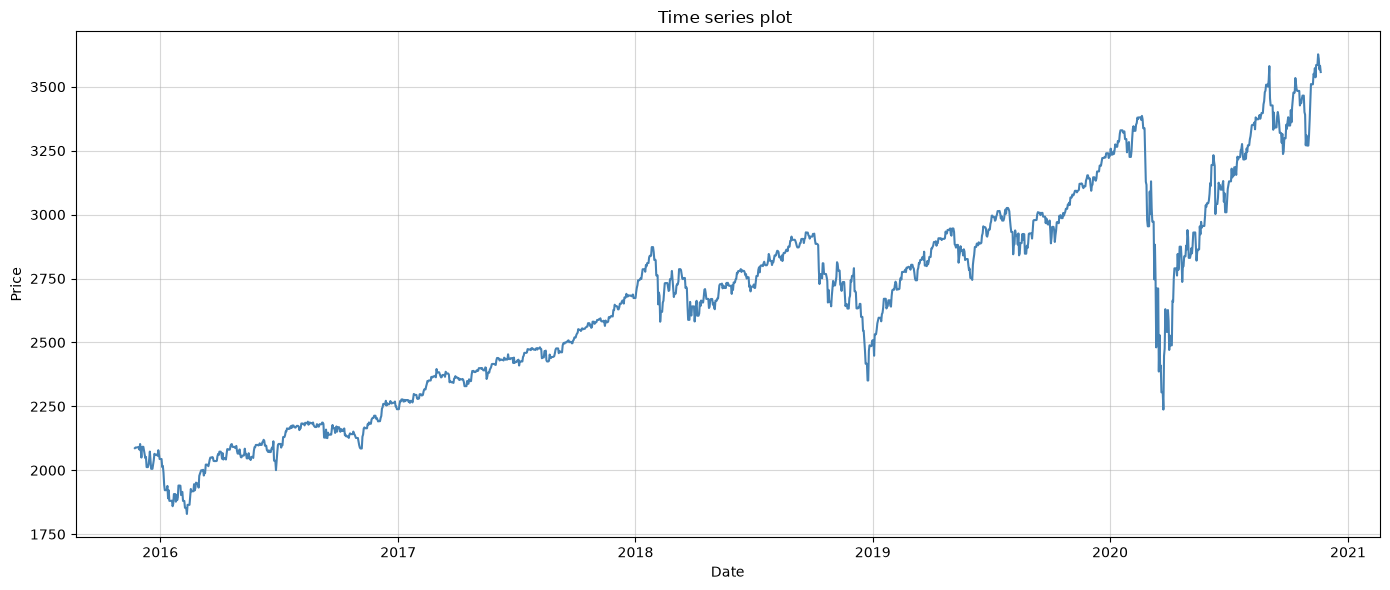

In [32]:
plt.figure(figsize=(14,6))
plt.plot(data.index,data["Close"],color="steelblue",linewidth=1.5)
plt.title("Time series plot ")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(True,alpha=0.5)
plt.tight_layout()
plt.show()

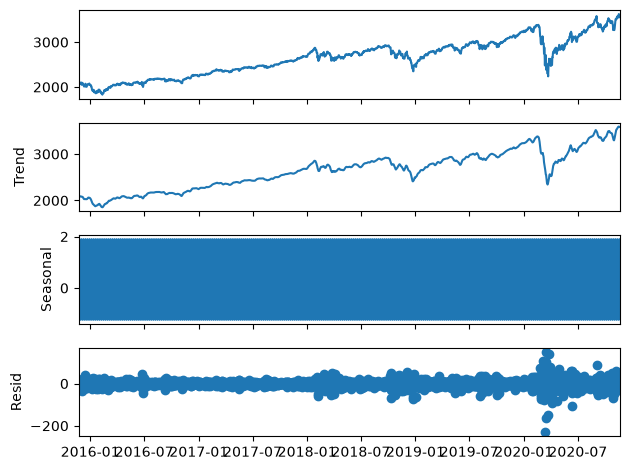

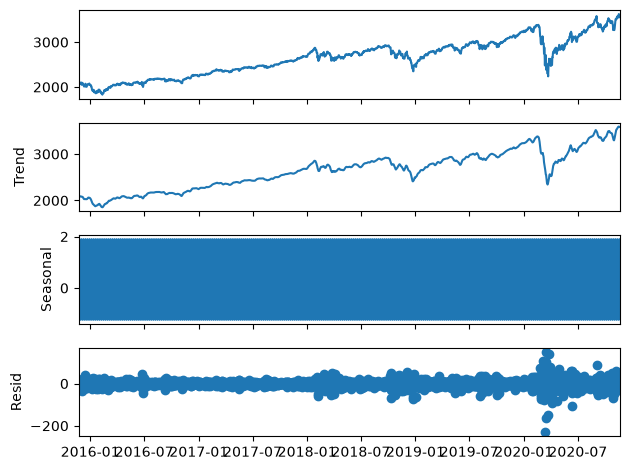

In [36]:
decomposition= seasonal_decompose(data,model="additive")
decomposition.plot()

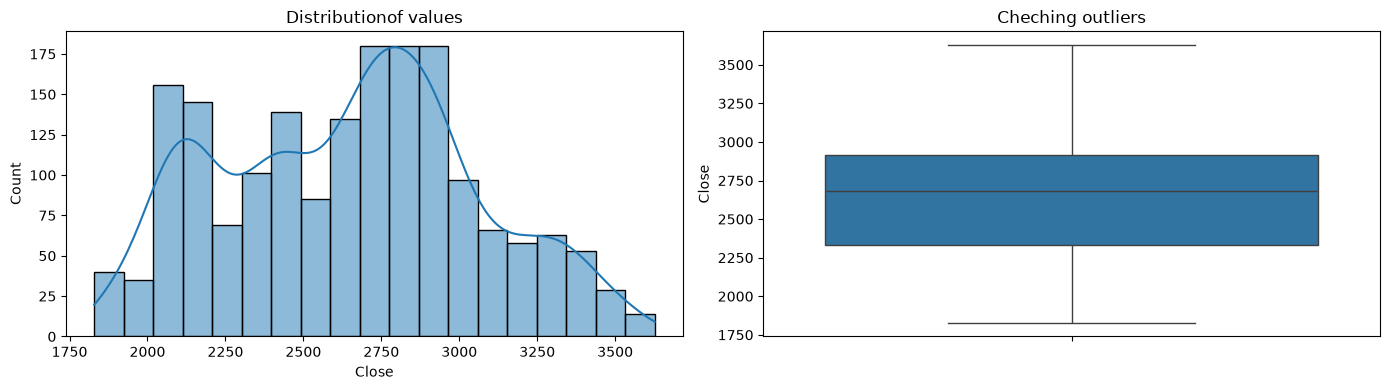

skewness:  0.081868595905298
Kurtosis:  -0.7655993955977114


In [40]:
fig,axis = plt.subplots(1,2,figsize=(14,4))

sns.histplot(data["Close"],kde=True,ax=axis[0])
axis[0].set_title("Distributionof values")

sns.boxplot(data["Close"],ax=axis[1])
axis[1].set_title("Cheching outliers")

plt.tight_layout()
plt.show()

print("skewness: ",data["Close"].skew())
print("Kurtosis: ",data["Close"].kurtosis())


In [42]:
adf_result= adfuller(data)
print("ADF test")
print("ADF statitics:",adf_result[0])
print("p-value:",adf_result[1])
print("Stationary according to ADF:",adf_result[1]<0.05)

ADF test
ADF statitics: -0.8703973870161158
p-value: 0.7975646340657557
Stationary according to ADF: False


In [45]:
data_diff1=data.diff()

In [50]:
data_diff1.dropna(inplace=True)

In [51]:
adf_result= adfuller(data_diff1)
print("ADF test")
print("ADF statitics:",adf_result[0])
print("p-value:",adf_result[1])
print("Stationary according to ADF:",adf_result[1]<0.05)

ADF test
ADF statitics: -8.522187682825937
p-value: 1.0930862670335744e-13
Stationary according to ADF: True


In [52]:
from statsmodels.tsa.stattools import acf
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_pacf,plot_pacf

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

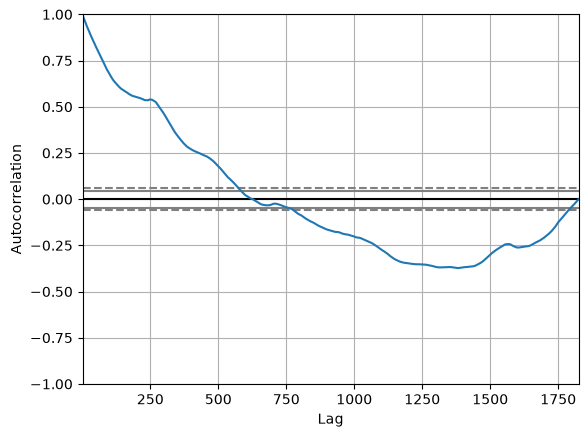

In [55]:
autocorrelation_plot(data)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

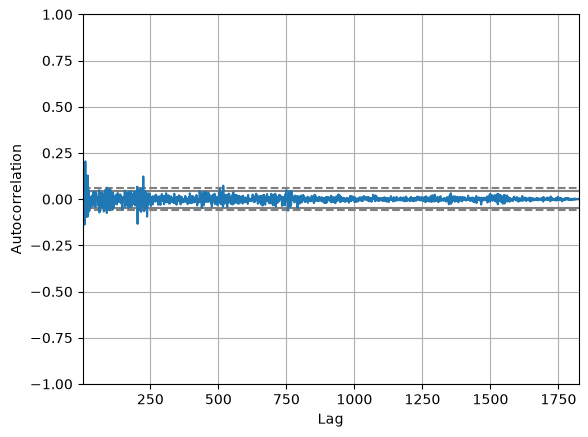

In [54]:
autocorrelation_plot(data_diff1)

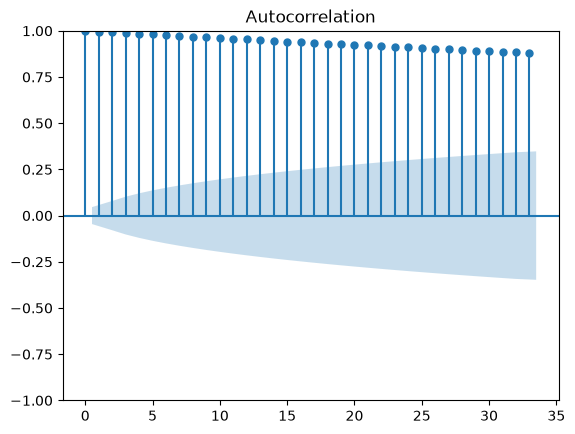

In [59]:
plot_acf(data)
plt.show()

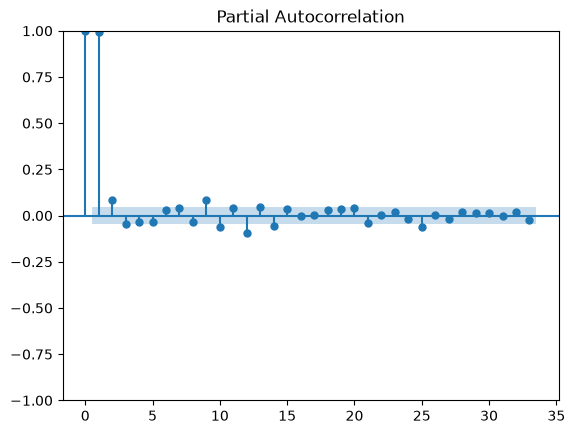

In [58]:
plot_pacf(data)
plt.show()

In [63]:
train_size = int(len(data)*0.8)
train,test = data[:train_size],data[train_size:]

In [65]:
p,d,q=1,1,1
model_arima = ARIMA(train,order=(p,d,q))
result_arima= model_arima.fit()
print(result_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1460
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -6228.332
Date:                Sun, 25 Oct 2026   AIC                          12462.664
Time:                        12:29:12   BIC                          12478.521
Sample:                    11-23-2015   HQIC                         12468.579
                         - 11-21-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0327      0.398     -0.082      0.935      -0.813       0.747
ma.L1         -0.0185      0.399     -0.046      0.963      -0.800       0.763
sigma2       298.6839      5.107     58.483      0.0

In [67]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
p,d,q,P,D,Q,s=3,1,1,1,1,1,12
model_sarima = SARIMAX(train,order=(p,d,q),seasonal_order=(P,D,Q,s))
result_sarima= model_sarima.fit()
print(result_sarima.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                 1460
Model:             SARIMAX(3, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -6196.046
Date:                            Sun, 25 Oct 2026   AIC                          12406.091
Time:                                    12:34:59   BIC                          12443.032
Sample:                                11-23-2015   HQIC                         12419.878
                                     - 11-21-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5419      0.159     -3.408      0.001      -0.854      -0.230
ar.L2         -0.0274      0.025   

In [75]:
forecast_arima = result_arima.predict(start=len(train), end=len(train)+len(test)-1)
forecast_sarima = result_sarima.predict(start=len(train), end=len(train)+len(test)-1)

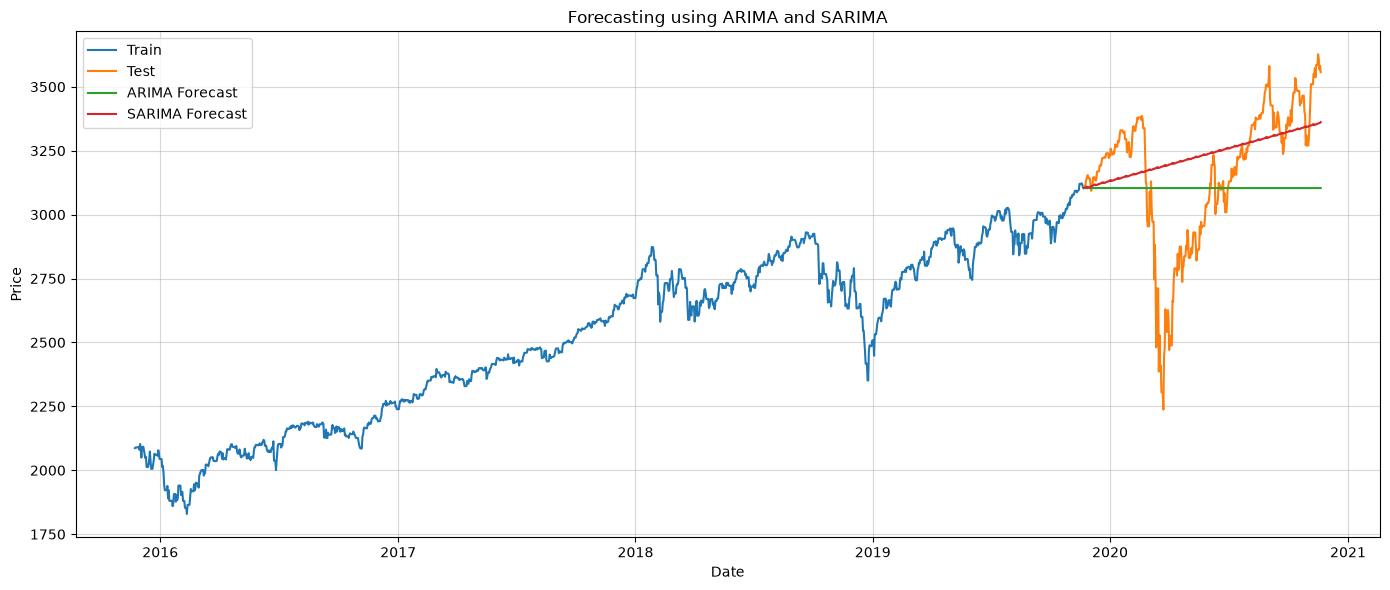

In [76]:
plt.figure(figsize=(14,6))
plt.plot(train,label="Train")
plt.plot(test,label="Test")
plt.plot(forecast_arima,label="ARIMA Forecast")
plt.plot(forecast_sarima,label="SARIMA Forecast")
plt.title("Forecasting using ARIMA and SARIMA")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True,alpha=0.5)
plt.tight_layout()
plt.show()

In [77]:
mae=mean_absolute_error(test,forecast_arima)
rmse=np.sqrt(mean_squared_error(test,forecast_arima))
print("ARIMA Forecasting Performance:")
print("Mean Absolute Error (MAE):",mae)
print("Root Mean Squared Error (RMSE):",rmse)


ARIMA Forecasting Performance:
Mean Absolute Error (MAE): 227.78612344224612
Root Mean Squared Error (RMSE): 278.4383066220404


In [78]:
mae=mean_absolute_error(test,forecast_sarima)
rmse=np.sqrt(mean_squared_error(test,forecast_sarima))
print("SARIMA Forecasting Performance:")
print("Mean Absolute Error (MAE):",mae)
print("Root Mean Squared Error (RMSE):",rmse)


SARIMA Forecasting Performance:
Mean Absolute Error (MAE): 188.48970249344137
Root Mean Squared Error (RMSE): 260.06775040529055
